Number of pedestrians detected: 23


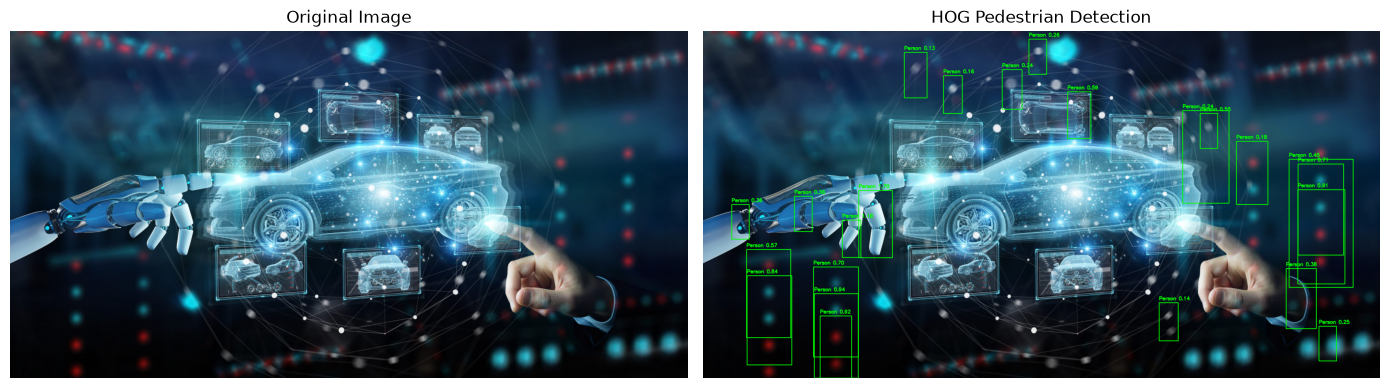

In [5]:
import cv2
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog

# Select image from computer
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

path = filedialog.askopenfilename(
    title="Select Pedestrian Image",
    filetypes=[("Image Files", "*.jpg *.jpeg *.png")]
)

root.destroy()

if not path:
    raise ValueError("No image selected")

# Read image
image = cv2.imread(path)

if image is None:
    raise FileNotFoundError("Image could not be loaded")

# Create HOG descriptor
hog = cv2.HOGDescriptor()

# Load pre-trained pedestrian detector
hog.setSVMDetector(
    cv2.HOGDescriptor_getDefaultPeopleDetector()
)

# Detect pedestrians
rects, weights = hog.detectMultiScale(
    image,
    winStride=(4, 4),
    padding=(8, 8),
    scale=1.03
)

# Draw bounding boxes
output = image.copy()

for (x, y, w, h), weight in zip(rects, weights):

    cv2.rectangle(
        output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        output,
        f"Person {float(weight):.2f}",
        (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

print("Number of pedestrians detected:", len(rects))

# Display original and detected images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("HOG Pedestrian Detection")
plt.axis("off")

plt.tight_layout()
plt.show()